In [1]:
import re
import os
import pandas as pd
import numpy as np
from Bio import SeqIO
from datetime import datetime
from plotnine import ggplot, geom_bar, aes, geom_col, labs, theme, element_blank, element_text

In [2]:
# Goal: see if you can get more fine-scale geographic data for your metadata

In [256]:
# STEP 1: import data

USDA_DETECTIONS = "./metadata/detections_data/HPAI Detections in Wild Birds (dwnld 2025-01-31).csv"
CAN_DETECTIONS = "./metadata/detections_data/HPAI_IAHP_Wildlife_Faune__file_fichie.csv"

#METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_pb2.tsv"
#METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_pb1.tsv"
#METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_pa.tsv"
#METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_ha.tsv"
#METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_np.tsv"
#METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_na.tsv"
#METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_m.tsv"
METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_ns.tsv"

In [257]:
us_detections = pd.read_csv(USDA_DETECTIONS, sep = ",")
can_detections = pd.read_csv(CAN_DETECTIONS, sep = ",")
#ha_metadata = pd.read_csv(METADATA, sep = "\t")
metadata = pd.read_csv(METADATA, sep = "\t")

In [258]:
metadata.head()
print(metadata.columns)

Index(['Unnamed: 0', 'SRA_Accession', 'strain_segment', 'Genome ID',
       'H5 Clade', 'SRA Accession', 'strain', 'h5_clade', 'source_merge2',
       'bvbrc_assembled', 'strain_segment_updated', 'genbank_acc', 'bp_length',
       'segment_no', 'nonambig_date', 'date', 'strain_title', 'division',
       'host_fromstrain', 'bird_order', 'domesticstatus_combined',
       'host_correction', 'NAflyway', 'state_lat-long', 'strain_title_updated',
       'year_only', 'month_only'],
      dtype='object')


In [259]:
# STEP 2: Make any edits to the metadata dataframe

In [260]:
# Subset the metadata to the necessary columns

# needed_columns = ["nonambig_date", "date", "strain_title_updated", "division", "host_fromstrain", "bird_order", "NAflyway", "domesticstatus_combined", 
#                   "year_only", "month_only"]

# ha_metadata_subset = ha_metadata.loc[0:, needed_columns]

In [261]:
# ha_metadata_subset_wild = ha_metadata_subset[ha_metadata_subset["domesticstatus_combined"] == "wild"]

In [262]:
metadata_wild = metadata[metadata["domesticstatus_combined"] == "wild"]

In [263]:
print(len(metadata))
#print(len(ha_metadata_subset))
#print(len(ha_metadata_subset_wild))
print(len(metadata_wild))

10291
6717


In [264]:
#metadata_hosts = pd.DataFrame(set(ha_metadata_subset_wild["host_fromstrain"]))
#metadata_hosts.to_csv("/Users/claramal/Desktop/metadata_hosts.csv", sep = ',')

In [12]:
# STEP 3: Make any edits to the US detections dataframe

In [13]:
print(len(us_detections))

11065


In [14]:
# Changes that need to be made to the US detections list:
# State: make lowercase, fix for any abbreviations
# County: make lowercase
# Collection Date: fix format to YYYY-MM-DD
# Date Detected: fix format to YYYY-MM-DD
# Bird Species: make lowercase, remove spaces/hyphens/apostrophes
# HPAI Strain: remove anything that isn't EA H5

In [15]:
# State: make lowercase, fix for any abbreviations

us_detections["State"] = us_detections["State"].str.replace(" ","")
us_detections["State"] = us_detections["State"].str.lower()

print(set(us_detections["State"]))

{'vermont', 'wyoming', 'southcarolina', 'montana', 'newjersey', 'kentucky', 'utah', 'illinois', 'louisiana', 'newhampshire', 'rhodeisland', 'alaska', 'minnesota', 'northcarolina', 'oregon', 'nevada', 'arizona', 'iowa', 'virginia', 'missouri', 'maryland', 'northdakota', 'delaware', 'alabama', 'mississippi', 'florida', 'california', 'tennessee', 'maine', 'kansas', 'michigan', 'nebraska', 'washington', 'texas', 'massachusetts', 'newyork', 'southdakota', 'colorado', 'pennsylvania', 'georgia', 'newmexico', 'oklahoma', 'connecticut', 'westvirginia', 'arkansas', 'indiana', 'hawaii', 'dc', 'wisconsin', 'idaho', 'ohio'}


In [16]:
# County: make lowercase, change all spaces/hyphens/dots to underscores

us_detections["County"] = us_detections["County"].str.replace("Parish", "")
us_detections["County"] = us_detections["County"].str.rstrip()
us_detections["County"] = us_detections["County"].str.lstrip()
us_detections["County"] = us_detections["County"].str.replace(".", "")
us_detections["County"] = us_detections["County"].str.replace(" ", "_")
us_detections["County"] = us_detections["County"].str.replace("-", "_")
us_detections["County"] = us_detections["County"].str.replace("'", "")
us_detections["County"] = us_detections["County"].str.lower()

In [17]:
print(set(us_detections["County"]))

{'salem', 'churchill', 'converse', 'addison', 'grafton', 'hughes', 'snohomish', 'canyon', 'vanderburgh', 'alachua', 'pemiscot', 'henry', 'chippewa', 'newaygo', 'isanti', 'siskiyou', 'faulk', 'bladen', 'orangeburg', 'chugach', 'camden', 'cross', 'sedgwick', 'dunklin', 'aurora', 'la_crosse', 'cortland', 'issaquena', 'sawyer', 'albany', 'smith', 'saginaw', 'gem', 'humphreys', 'colleton', 'aitkin', 'dawson', 'sonoma', 'iosco', 'baldwin', 'guilford', 'durham', 'somerset', 'delta', 'holt', 'buncombe', 'woodbury', 'norfolk', 'st_johns', 'nodaway', 'sargent', 'schoharie', 'chittenden', 'nobles', 'hartford', 'mackinac', 'tattnall', 'chemung', 'robertson', 'mccormick', 'buchanan', 'breckinridge', 'gallatin', 'nueces', 'minnehaha', 'toole', 'kewanee', 'neshoba', 'wicomico', 'leflore', 'tarrant', 'dutchess', 'socorro', 'santa_clara', 'charles', 'yellowstone', 'granville', 'shasta', 'sanborn', 'cheyenne', 'rooks', 'beadle', 'yates', 'antrim', 'monroe', 'platte', 'montgomery', 'noxubee', 'duchesne',

In [18]:
# Make a state_county column

us_detections["state_county"] = us_detections["State"] + '_' + us_detections["County"]

In [19]:
# Some changes have to be made because of incorrect spellings in the detections data

incorrect_statecounty_detectionsdf = {"louisiana_la_salle":"louisiana_lasalle",
                                      "mississippi_de_soto":"mississippi_desoto",
                                      "maryland_st_mary":"maryland_st_marys",
                                      "wisconsin_burnet":"wisconsin_burnett",
                                      "newyork_rensselear":"newyork_rensselaer",
                                      "wisconsin_kewanee":"wisconsin_kewaunee",
                                      "southdakota_stutsman":"northdakota_stutsman",
                                      "southdakota_dickey":"northdakota_dickey",
                                      "virginia_matthews":"virginia_mathews",
                                      "virginia_norfolk_city":"virginia_norfolk"
                                     }

for original_name, corrected_name in incorrect_statecounty_detectionsdf.items():
        us_detections["state_county"] = us_detections["state_county"].replace(original_name, corrected_name)

In [20]:
# Quick check: which Alaskan counties are in the detections data

alaska_detections = us_detections[us_detections["State"] == "alaska"]
print(alaska_detections["County"].value_counts())

# Quick check: which Virginian counties are in the detections data

virginia_detections = us_detections[us_detections["State"] == "virginia"]
print(virginia_detections["County"].value_counts())

County
matanuska_susitna       108
aleutians_east           67
juneau                   35
anchorage                24
sitka                    23
north_slope              21
aleutians_west           18
dillingham               18
bethel                   13
southeast_fairbanks      13
kusilvak                  8
kenai_peninsula           6
fairbanks_north_star      4
nome                      3
yukon_koyukuk             3
ketchikan_gateway         2
haines                    2
valdez_cordova            2
northwest_arctic          1
chugach                   1
Name: count, dtype: int64
County
henrico           18
norfolk           15
surry             10
essex              6
chesterfield       6
virginia_beach     5
waynesboro         5
hampton            5
fluvanna           4
orange             3
loudoun            3
prince_william     2
matthews           2
clarke             2
powhatan           2
king_george        2
accomack           1
middlesex          1
pittsylvania       1
k

In [21]:
# Collection Date: fix format to YYYY-MM-DD
# Date Detected: fix format to YYYY-MM-DD

Collection_Date_unknowns = us_detections["Collection Date"].value_counts().get('Unknown', 0)
print(Collection_Date_unknowns)

Date_Detected_nulls = us_detections["Date Detected"].value_counts().get('null', 0)
print(Date_Detected_nulls)

190
0


In [22]:
# Change the dates in Collection Date (US detections)

us_collect_date_unknowns = []

for index, row in us_detections.iterrows():
    # Ensure the "Collection Date" is not null and is in the expected format
    date_str = row["Collection Date"]
    
    # Check if the date is not null and contains exactly 2 slashes
    if isinstance(date_str, str) and date_str.count("/") == 2:
        # Split the date into month, day, and year
        month, day, year = date_str.split("/")
        
        # Add leading zero to month and day if necessary
        month = month.zfill(2)
        day = day.zfill(2)
        
        # Create the formatted date string in "YYYY-MM-DD" format
        us_detections.at[index, "collect_date"] = f"{year}-{month}-{day}"
    else:
        # Handle invalid date format or missing data (optional)
        # print(f"Skipping invalid date format at index {index}: {date_str}")
        us_collect_date_unknowns.append(index)
        us_detections.at[index, "collect_date"] = None  # Set as None or handle accordingly

In [23]:
# Check to confirm

print(len(us_collect_date_unknowns))

190


In [24]:
# Change the dates in Date Detected

us_detect_date_unknowns = []

for index, row in us_detections.iterrows():
    # Ensure the "Date Detected" is not null and is in the expected format
    date_str = row["Date Detected"]
    
    # Check if the date is not null and contains exactly 2 slashes
    if isinstance(date_str, str) and date_str.count("/") == 2:
        # Split the date into month, day, and year
        month, day, year = date_str.split("/")
        
        # Add leading zero to month and day if necessary
        month = month.zfill(2)
        day = day.zfill(2)
        
        # Create the formatted date string in "YYYY-MM-DD" format
        us_detections.at[index, "detect_date"] = f"{year}-{month}-{day}"
    else:
        # Handle invalid date format or missing data (optional)
        # print(f"Skipping invalid date format at index {index}: {date_str}")
        us_detect_date_unknowns.append(index)
        us_detections.at[index, "detect_date"] = None  # Set as None or handle accordingly

In [25]:
# Check to confirm

print(len(us_detect_date_unknowns))

23


In [26]:
# Bird Species: make lowercase, remove spaces/hyphens/apostrophes

us_detections_hosts = pd.DataFrame(set(us_detections["Bird Species"]))
print(len(us_detections_hosts))

225


In [27]:
# Print a CSV of the hosts so you can assign synonyms

# total_hosts_2.to_csv("./metadata/helpful_lists/host_synonyms_HPAIdetections.csv", sep = ",")

In [28]:
# Function: drop the hybrid, remove (unidentified), and replace "northenpintail" with "northernpintail"

def alter_us_detections_hosts(df):
    # Loop through DataFrame rows
    df["Bird Species"] = df["Bird Species"].astype(str).str.replace(" ", "", regex=False).str.replace("'", "", regex=False).str.replace("-", "", regex=False).str.lower()
    
    for index, row in df.iterrows():
        host_name = str(row["Bird Species"])

        # First, remove the mallard/blackduckhybrid cause it's weird
        if host_name == "mallard/blackduckhybrid":
            df.drop(index, axis=0, inplace=True)  # Drop row in-place

        # Fix the typo in "northenpintail"
        elif host_name == "northenpintail":  # Correct typo check
            host_name = host_name.replace("northenpintail", "northernpintail")
            df.at[index, "Bird Species"] = host_name  # Update the DataFrame

        # Remove "(unidentified)" from species names
        elif "(unidentified)" in host_name:  # Check if "(unidentified)" is in the name
            host_name = host_name.replace("(unidentified)", "")
            df.at[index, "Bird Species"] = host_name  # Update the DataFrame

        # Remove "(anatidae)" from species names
        elif "(anatidae)" in host_name:  # Check if "(unidentified)" is in the name
            host_name = host_name.replace("(anatidae)", "")
            df.at[index, "Bird Species"] = host_name  # Update the DataFrame

    return df

In [29]:
# Run the above function to fix the bird species names 

us_detections = alter_us_detections_hosts(us_detections)

In [30]:
# Then download the most recent host list, turn it into a dictionary, and use it to assign corrected species names

host_names_df = pd.read_csv("./metadata/helpful_lists/NAm_host_list_order-domesticstat.csv", sep = ",", encoding='latin-1')

host_names_dict = host_names_df.set_index("strain_host").to_dict(orient="index")

for idx, row in us_detections.iterrows():
    # Check if strain_host exists in the dictionary
    host = row["Bird Species"]
    if host in host_names_dict:
        us_detections.loc[idx, "order"] = host_names_dict[host]["order"]
        us_detections.loc[idx, "domesticstatus"] = host_names_dict[host]["domesticstatus"]
        us_detections.loc[idx, "corrected_host"] = host_names_dict[host]["corrected_host"]

In [31]:
# HPAI Strain: remove anything that isn't EA H5

print(us_detections["HPAI Strain"].value_counts())

strains_to_keep = ["EA H5N1", "EA/AM H5N1", "EA H5N1 mixed", "EA H5N1 Mixed"]

us_detections_H5N1 = us_detections[us_detections["HPAI Strain"].isin(strains_to_keep)]

HPAI Strain
EA H5N1             5297
EA/AM H5N1          4355
EA H5               1287
EA H5N1 mixed         65
EA H5 mixed           33
EA H5N5                8
EA/AM H5               5
EA/AM H5 mixed         3
EA/AM H5N1 mixed       3
EA/AM H5N6             3
EA H5N1 Mixed          1
Name: count, dtype: int64


In [32]:
print(len(us_detections_H5N1))
us_detections_H5N1.head()

9718


,State,County,Collection Date,Date Detected,HPAI Strain,Bird Species,WOAH Classification,Sampling Method,Submitting Agency,state_county,collect_date,detect_date,order,domesticstatus,corrected_host
0,texas,travis,1/3/2025,1/27/2025,EA/AM H5N1,duck,Wild bird,Morbidity/Mortality,Private (non-government) submission,texas_travis,2025-01-03,2025-01-27,anseriformes,unknown,duck
10,alaska,aleutians_east,10/9/2023,1/24/2025,EA H5N1,mallard,Wild bird,Morbidity/Mortality,SCWDS,alaska_aleutians_east,2023-10-09,2025-01-24,anseriformes,wild,mallard
11,alaska,aleutians_east,10/9/2023,1/24/2025,EA H5N1,northernpintail,Wild bird,Morbidity/Mortality,SCWDS,alaska_aleutians_east,2023-10-09,2025-01-24,anseriformes,wild,northernpintail
12,alaska,aleutians_east,10/9/2023,1/24/2025,EA H5N1,northernpintail,Wild bird,Morbidity/Mortality,SCWDS,alaska_aleutians_east,2023-10-09,2025-01-24,anseriformes,wild,northernpintail
13,alaska,aleutians_east,10/9/2023,1/24/2025,EA H5N1,northernpintail,Wild bird,Morbidity/Mortality,SCWDS,alaska_aleutians_east,2023-10-09,2025-01-24,anseriformes,wild,northernpintail


In [33]:
# STEP 4: Make edits to the Canadian detections datasets

In [34]:
# Changes that need to be made to the Canadian detections list:
# Animal Class: limit to "Avian"
# Province: make lowercase, fix for any abbreviations, change column title to "State"
# CCSNAME: make lowercase, remove symbols, change column title to "county"
# Collection Date: fix format to YYYY-MM-DD
# Result Authorised Date: don't need
# Common Name: make lowercase, remove spaces/hyphens/apostrophes

In [35]:
print(len(can_detections))

2858


In [36]:
# Animal Class: limit to "Avian"

can_detections_aves = can_detections[can_detections["Animal Class"] == "Avian"]

In [37]:
# Province: make lowercase, fix for any abbreviations, change column title to "State"

can_detections_aves_filt = can_detections_aves[can_detections_aves["Province"] != "Atlantic Ocean"]
can_detections_aves_filt["Province"] = can_detections_aves_filt["Province"].str.replace(" ","")
can_detections_aves_filt["Province"] = can_detections_aves_filt["Province"].str.lower()
can_detections_aves_filt = can_detections_aves_filt.rename({"Province":"State"}, axis = 1)

print(set(can_detections_aves_filt["State"]))

{'alberta', 'newfoundlandandlabrador', 'quebec', 'newbrunswick', 'yukon', 'manitoba', 'britishcolumbia', 'ontario', 'saskatchewan', 'princeedwardisland', 'novascotia', 'northwestterritories', 'nunavut'}


/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_62402/30306940.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_62402/30306940.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [38]:
can_county_symbols = {"  ":" ",
                     ". ":"_",
                     ", ":"_",
                     " - ":"_",
                     "--":"_",
                     " / ":"_",
                     "'":"",
                     "(":"",
                     ")":"",
                     "!":"",
                     "&":"and",
                     "é":"e",
                     "è":"e",
                     "ò":"o",
                     "í":"i",
                     "ì":"i",
                     "à":"a",
                     "á":"a",
                     "ú":"u",
                     "ù":"u",
                     "â":"a",
                     "ô":"o",
                     "ê":"e",
                     "ï":"i",
                     "ü":"u",
                     "ë":"e",
                     "ç":"c",
                    }

In [39]:
def replace_symbols(text):
    if isinstance(text, str):
        for symbol, replacement in can_county_symbols.items():
            text = text.replace(symbol, replacement)
    return text

In [40]:
# Function: reorganize can_counties_subset_renamed

def fix_cancounties_dataframe(df):

    df_final = df.copy()

    #Fix the county column
    df_final["County"] = df_final["CCSNAME"]
    df_final["County"] = df_final["County"].str.rstrip()
    df_final["County"] = df_final["County"].str.replace("Î", "i") # have to change this outside of the function, otherwise it won't work
    df_final["County"] = df_final["County"].str.lower()


    df_final["County"] = df_final["County"].apply(replace_symbols)
    
    # Fix these outside of the dictionary because otherwise the apply function will confuse with "  ", " - ", and " / "
    df_final["County"] = df_final["County"].str.replace(" ", "_")
    df_final["County"] = df_final["County"].str.replace("-", "_")
    df_final["County"] = df_final["County"].str.replace("/", "_")

    # If "County" is NaN, put "unknown" in state_county, otherwise put the state and county
    df_final["state_county"] = np.where(df_final["County"].isna(), df_final["State"] + "_unknown", df_final["State"] + "_" + df_final["County"])

    return(df_final)

In [41]:
# Make the final can_counties dataframe

can_detections_aves_filt2 = fix_cancounties_dataframe(can_detections_aves_filt)

In [42]:
print(len(set(can_detections_aves_filt2["state_county"])))

572


In [43]:
# Two incorrect detections in the Canadian dataset
# Coaticook and Compton are in Quebec, not Ontario

can_corrections_dict = {"ontario_coaticook":"quebec_coaticook",
                        "ontario_compton":"quebec_compton"
                       }

for original_name, corrected_name in can_corrections_dict.items():
        can_detections_aves_filt2["state_county"] = can_detections_aves_filt2["state_county"].replace(original_name, corrected_name)

In [44]:
# Collection Date: fix format to YYYY-MM-DD

can_collect_date_unknowns = []

for index, row in can_detections_aves_filt2.iterrows():
    # Ensure the "Collection Date" is not null and is in the expected format
    date_str = row["Collection Date"]
#    print(can_detections_aves_filt2["Collection Date"])
    
    # Check if the date is not null and contains exactly 2 slashes
    if isinstance(date_str, str) and date_str.count(".") == 2:
        # Split the date into month, day, and year
        year = date_str.split(".")[0]
        month = date_str.split(".")[1]
        day = date_str.split(".")[2]
        
        # Add leading zero to month and day if necessary
        month = month.zfill(2)
        day = day.zfill(2)
        
        # Create the formatted date string in "YYYY-MM-DD" format
        can_detections_aves_filt2.at[index, "collect_date"] = f"{year}-{month}-{day}"
    else:
        # Handle invalid date format or missing data (optional)
        print(f"Skipping invalid date format at index {index}: {date_str}")
        can_collect_date_unknowns.append(index)
        can_detections_aves_filt2.at[index, "collect_date"] = None  # Set as None or handle accordingly

In [45]:
# Check to confirm

print(len(can_collect_date_unknowns))

0


In [46]:
# Common Name: make lowercase, remove spaces/hyphens/apostrophes

can_detections_aves_filt3 = can_detections_aves_filt2.copy()

can_detections_aves_filt3["Common Name"] = can_detections_aves_filt3["Common Name"].str.replace(" ", "").str.replace("'", "").str.replace("-", "")
can_detections_aves_filt3["Common Name"] = can_detections_aves_filt3["Common Name"].str.lower()
# Also remove "(duck)", "(gullsandterns)", "(anatidae)"
can_detections_aves_filt3["Common Name"] = can_detections_aves_filt3["Common Name"].str.replace("(duck)", "").str.replace("(gullsandterns)", "").str.replace("(anatidae)", "")

print(len(set(can_detections_aves_filt3["Common Name"])))

canada_detections_hosts = pd.DataFrame(set(can_detections_aves_filt3["Common Name"]))
print(len(canada_detections_hosts))

100
100


In [47]:
# Print a list of all detections hosts

all_detections_hosts = pd.concat([us_detections_hosts, canada_detections_hosts], axis = 0)
all_detections_hosts_deduped = all_detections_hosts.drop_duplicates(subset = 0, keep = "first")
print(len(all_detections_hosts_deduped))

#all_detections_hosts_deduped.to_csv("./metadata/detections_data/detections_hosts.csv", sep = ',')

324


In [48]:
# Then download the most recent host list, turn it into a dictionary, and use it to assign corrected species names

for idx, row in can_detections_aves_filt3.iterrows():
    # Check if strain_host exists in the dictionary
    host = row["Common Name"]
    if host in host_names_dict:
        can_detections_aves_filt3.loc[idx, "order"] = host_names_dict[host]["order"]
        can_detections_aves_filt3.loc[idx, "domesticstatus"] = host_names_dict[host]["domesticstatus"]
        can_detections_aves_filt3.loc[idx, "corrected_host"] = host_names_dict[host]["corrected_host"]

In [49]:
# STEP 5: add county-level coordinates to the detections datasets

In [50]:
# Make dictionary of county coordinates

NAm_counties = pd.read_csv("./metadata/detections_data/NAm_counties.tsv", sep = "\t")

NAm_counties_dict = NAm_counties.set_index("state_county").to_dict(orient="index")

In [51]:
# Add the centroid of each county to the US detections dataframe in the county_centroid column

us_detections_final_coords = us_detections_H5N1.copy()

for idx, row in us_detections_final_coords.iterrows():
    # Check if 'state_county' exists in the dictionary
    state_county = row["state_county"]
    if state_county in NAm_counties_dict:
        # Assign the lat_long value from us_counties_dict to 'county_centroid'
        us_detections_final_coords.loc[idx, "county_centroid"] = NAm_counties_dict[state_county]["lat_long"]

In [52]:
# Add the centroid of each county to the Canadian detections dataframe in the county_centroid column

can_detections_final_coords = can_detections_aves_filt3.copy()

for idx, row in can_detections_final_coords.iterrows():
    # Check if 'state_county' exists in the dictionary
    state_county = row["state_county"]
    if state_county in NAm_counties_dict:
        # Assign the lat_long value from us_counties_dict to 'county_centroid'
        can_detections_final_coords.loc[idx, "county_centroid"] = NAm_counties_dict[state_county]["lat_long"]

can_detections_final_coords["city_centroid"] = "unknown"

In [53]:
# For ease, change any NaN in the county_centroid column of the US detections dataset to "unknown"

us_detections_final_coords.loc[us_detections_final_coords["county_centroid"].isna(), "county_centroid"] = "unknown"

In [54]:
# Have to manually add in coordinates for Connecticut counties (because the census doesn't recognize those anymore)

remaining_county_assignments = {"connecticut_new_haven":"41.35, -72.9",
                                "connecticut_middlesex":"41.44, -72.52",
                                "connecticut_hartford":"41.81, -72.73",
                                "connecticut_new_london":"41.47, -72.1",
                                "connecticut_tolland":"41.85, -72.33",
                                "connecticut_fairfield":"41.23, -73.37",
                                "connecticut_windham":"41.83, -71.99",
                                "connecticut_litchfield":"41.79, -73.24",
                               }

# Some entries in the detections dataset have city designations, even though they are labeled as county
# Partially this is due to the weird situation in Viginia, where there are counties AND independent cities
# We would like whatever is the most fine-scale coordinate, so I will add these to a city_centroid column

remaining_city_assignments = {"texas_shenandoah":"30.179722, -95.455278", # For city designations, used the coordinates of the city as per GeoHack
                              "indiana_bloomington":"39.162222, -86.522222", # For city designations, used the coordinates of the city as per GeoHack
                              "virginia_norfolk":"36.846944, -76.285278", # For independent cities, used the centroid of the municipality, as given on GeoHack
                              "virginia_hampton":"37.026389, -76.344444", # For independent cities, used the centroid of the municipality, as given on GeoHack
                              "virginia_waynesboro":"39.748889, -77.581389", # For independent cities, used the centroid of the municipality, as given on GeoHack
                              "virginia_virginia_beach":"36.85, -75.977778", # For independent cities, used the centroid of the municipality, as given on GeoHack
                              "virginia_chesapeake":"36.714167, -76.238333" # For independent cities, used the centroid of the municipality, as given on GeoHack
                             }

In [55]:
# Add in remaining counties (connecticut) and cities

us_detections_final_coords_updt = us_detections_final_coords.copy()

us_detections_final_coords_updt["city_centroid"] = "unknown"

# Loop over the rows to fill missing lat_long values using the dictionary
for idx, row in us_detections_final_coords_updt.iterrows():
    state_county = row["state_county"]
    # Check if state_county has a corresponding lat_long in the dictionary
    if (row["county_centroid"] == "unknown" ) and state_county in remaining_county_assignments:
        # Update the lat_long value using the dictionary
        us_detections_final_coords_updt.at[idx, "county_centroid"] = remaining_county_assignments[state_county]
    elif (row["county_centroid"] == "unknown") and state_county in remaining_city_assignments:
        # Update the lat_long value using the dictionary
        us_detections_final_coords_updt.at[idx, "city_centroid"] = remaining_city_assignments[state_county]
    else:
        pass

In [56]:
# This should check for state_county with no county_centroid and no city_centroid

no_us_centroid_updt = us_detections_final_coords_updt[
    (us_detections_final_coords_updt["county_centroid"] == "unknown") & (us_detections_final_coords_updt["city_centroid"] == "unknown")]

no_centroid = pd.concat([no_us_centroid_updt, can_detections_final_coords[can_detections_final_coords["county_centroid"] == "unknown"]], 
                        axis = 0,
                        join = "outer")

print(no_centroid["state_county"].value_counts())

state_county
britishcolumbia_langley           25
ontario_hamilton                  22
manitoba_portage_la_prairie       19
princeedwardisland_souris         18
alberta_taber                      8
novascotia_lunenburg               5
newbrunswick_gagetown              4
newbrunswick_sussex                4
princeedwardisland_tignish         4
newbrunswick_caraquet              3
newbrunswick_moncton               3
manitoba_morris                    3
novascotia_digby                   2
newbrunswick_chipman               2
princeedwardisland_miscouche       2
alaska_valdez_cordova              2
newbrunswick_shippagan             2
novascotia_yarmouth                2
quebec_saint_isidore               1
princeedwardisland_wellington      1
manitoba_ste_anne                  1
novascotia_shelburne               1
idaho_starke                       1
newbrunswick_sackville             1
princeedwardisland_oleary          1
quebec_notre_dame_de_lourdes       1
princeedwardisland_north_

In [57]:
# Concatenate the two detections lists

full_NAm_detections = pd.concat([us_detections_final_coords_updt, can_detections_final_coords], axis = 0, join = "outer")

print(len(full_NAm_detections))

12399


In [58]:
# Are any state_county rows NaN
print(full_NAm_detections["state_county"].isna().value_counts())

# Are any State rows NaN
print(full_NAm_detections["State"].isna().value_counts())

# Are any collect_date rows NaN
print(full_NAm_detections["collect_date"].isna().value_counts())

# Are any corrected_host rows NaN
print(full_NAm_detections["corrected_host"].isna().value_counts())
#print(full_NAm_detections[full_NAm_detections["corrected_host"].isna()])

# Are any county_centroid rows NaN
print(full_NAm_detections["county_centroid"].isna().value_counts())
#print(full_NAm_detections[full_NAm_detections["county_centroid"].isna()])

# Are any city_centroid rows NaN
print(full_NAm_detections["city_centroid"].isna().value_counts())

state_county
False    12399
Name: count, dtype: int64
State
False    12399
Name: count, dtype: int64
collect_date
False    12216
True       183
Name: count, dtype: int64
corrected_host
False    12399
Name: count, dtype: int64
county_centroid
False    12390
True         9
Name: count, dtype: int64
city_centroid
False    12399
Name: count, dtype: int64


In [265]:
# STEP 6: add coordinates to sequencing data via detections data

In [266]:
# Comparison: if species, state, AND date detected matches, then add county to metadata in that row

In [267]:
# Loop: Attempt 1

# for row in ha_metadata_subset:
#     if row["date"] in detections_H5N1_newcolumns["date"].at(idx):
#         try:
#             if row["division"] in detections_H5N1_newcolumns["division"].at(idx):
#                 finally:
#                     if row["host_fromstrain"] in detections_H5N1_newcolumns["host_fromstrain"].at(idx):
#                         ha_metadata_subset["county"] = detections_H5N1_newcolumns["County"].at(idx)
#     else:
#         ha_metadata_subset["county"].isna()

In [268]:
# Function: what to do when a matching row(s) exists 
# This function is intended as a nesting function inside the next function

def filling_rows(metadata_finescale, idx, matching_rows):
    
    unique_counties_in_match = set(matching_rows["County"].tolist())
    
    # if matching rows exist, this function will follow a specific set of instructions
    if len(unique_counties_in_match) == 1: 
                # If there is one "county" match and it is actually a county (i.e. middlesex), add the county and county_centroid
                if not matching_rows["county_centroid"].iloc[0] == "unknown":
                    metadata_finescale.at[idx, "county"] = matching_rows["County"].iloc[0]
                    metadata_finescale.at[idx, "city"] = "unknown"
                    metadata_finescale.at[idx, "county_lat-long"] = matching_rows["county_centroid"].iloc[0]
                    metadata_finescale.at[idx, "city_lat-long"] = "unknown"
                # If there is one "county" match but it is actually a city (i.e. virginia_beach), add the city and city_centroid
                elif (matching_rows["county_centroid"].iloc[0] == "unknown") and not (matching_rows["city_centroid"].iloc[0] == "unknown"):
                    metadata_finescale.at[idx, "county"] = "unknown"
                    metadata_finescale.at[idx, "city"] = matching_rows["County"].iloc[0]
                    metadata_finescale.at[idx, "county_lat-long"] = "unknown"
                    metadata_finescale.at[idx, "city_lat-long"] = matching_rows["city_centroid"].iloc[0]
                # If the "county" match is "unknown" and there is no "city" match
                elif (matching_rows["county_centroid"].iloc[0] == "unknown") and (matching_rows["city_centroid"].iloc[0] == "unknown"):
                    metadata_finescale.at[idx, "county"] = "unknown"
                    metadata_finescale.at[idx, "city"] = "unknown"
                    metadata_finescale.at[idx, "county_lat-long"] = "unknown"
                    metadata_finescale.at[idx, "city_lat-long"] = "unknown"
                else:
                    print(f"Unexpected condition at index {idx}")
                    
    # If there is more than one "county" match in matching rows
    elif len(unique_counties_in_match) > 1:
        metadata_finescale.at[idx, "county"] = "unknown"
        metadata_finescale.at[idx, "city"] = "unknown"
        metadata_finescale.at[idx, "county_lat-long"] = "unknown"
        metadata_finescale.at[idx, "city_lat-long"] = "unknown"

    # If no matching rows are found, set county to "unknown"
    else:
        print(f"Unexpected case (no matching counties) at index {idx}")

    return(metadata_finescale)

In [269]:
# Function: how to detect and fill matching rows

def matching_datehostdivision(metadata, detections):

    metadata_finescale = metadata.copy()
    
    for idx, row in metadata_finescale.iterrows():
        # Find rows in detections_H5N1_newcolumns that match the current row's values
        matching_rows = detections[
            (detections["collect_date"] == row["date"]) &
            (detections["State"] == row["division"]) &
            (detections["corrected_host"] == row["host_fromstrain"])
        ]

        # counties in match is just a list of the counties in the matched rows; eg: ["lake","granite"] or ["lake","lake","lake"]
        counties_in_match = matching_rows["County"].tolist()
        # unique counties in match is a set of the counties in matched rows; eg: {"lake","granite"} or {"lake"}
        unique_counties_in_match = set(matching_rows["County"].tolist())

        
        # If matching rows exist, assign the corresponding county or value
        if not matching_rows.empty:
            metadata_finescale = filling_rows(metadata_finescale, idx, matching_rows)
        else: 
            metadata_finescale.at[idx, "county"] = "unknown" 
            metadata_finescale.at[idx, "county_lat-long"] = "unknown" 
            metadata_finescale.at[idx, "city"] = "unknown" 
            metadata_finescale.at[idx, "city_lat-long"] = "unknown"

    return(metadata_finescale)

In [270]:
metadata_NAm_county = matching_datehostdivision(metadata_wild, full_NAm_detections)

In [271]:
# Check for length (did this process delete any rows)

print(len(metadata_wild))
print(len(metadata_NAm_county))

6717
6717


In [272]:
# Check for duplicates (did this process duplicate any rows)

print(metadata_NAm_county["strain_title_updated"].is_unique)

True


In [273]:
# What percentage of rows have an entry in the county column

print(metadata_NAm_county["county"].value_counts())

# What percentage of rows have an entry in the city column 

print(metadata_NAm_county["city"].value_counts())

county
unknown           2687
barnstable         116
brevard            112
aleutians_east      98
essex               89
                  ... 
burnet               1
genesee              1
sumter               1
suwannee             1
racine               1
Name: count, Length: 851, dtype: int64
city
unknown           6695
norfolk             12
hampton              8
virginia_beach       1
norfolk_city         1
Name: count, dtype: int64


In [274]:
# Heres the situation: 
# Point 1: detections for both Canada and the US are for wildlife, and don't include domestic detections
# Point 2: the four sequences from Newfoundland in mid-December 2021 (the start of the outbreak) are in domestic birds
# So, I have to add in those four sequences to this metadata with county detections

metadata_firstfour = metadata[(metadata["year_only"] == 2021) & (metadata["division"] == "newfoundland")]

# Add these four to metadata_NAm_county
metadata_NAm_county_withfirstfour = pd.concat([metadata_NAm_county, metadata_firstfour], axis = 0, join = "outer")
print(len(metadata_NAm_county_withfirstfour))

# Create a boolean mask for rows in metadata_NAm_county where strain is in metadata_firstfour["strain"]
mask = metadata_NAm_county_withfirstfour["strain"].isin(metadata_firstfour["strain"])

# Set the columns to "unknown" where mask is True
metadata_NAm_county_withfirstfour.loc[mask, ["county", "county_lat-long", "city", "city_lat-long"]] = "unknown"

# Check
print(metadata_NAm_county_withfirstfour[metadata_NAm_county_withfirstfour["strain"] == "a/domesticgoose/nl/fav003517/2021|2021-12-17|domestic|anseriformes|AtlanticFlyway"])
# print(metadata_NAm_county_withfirstfour[metadata_NAm_county_withfirstfour["strain"] == "a/fancychicken/nl/fav0035/2021|2021-12-17|domestic|galliformes|AtlanticFlyway"])
print(metadata_NAm_county_withfirstfour["county"].value_counts())

6721
      Unnamed: 0 SRA_Accession                       strain_segment  \
4636       50595           NaN  a/domesticgoose/nl/fav003517/2021_8   

      Genome ID H5 Clade SRA Accession  \
4636        NaN      NaN           NaN   

                                                 strain h5_clade  \
4636  a/domesticgoose/nl/fav003517/2021|2021-12-17|d...        ?   

     source_merge2 bvbrc_assembled  ... host_correction        NAflyway  \
4636        gisaid              no  ...   domesticgoose  AtlanticFlyway   

      state_lat-long               strain_title_updated year_only month_only  \
4636     48.36,-56.2  a/domesticgoose/nl/fav003517/2021      2021         12   

       county     city county_lat-long city_lat-long  
4636  unknown  unknown         unknown       unknown  

[1 rows x 31 columns]
county
unknown           2691
barnstable         116
brevard            112
aleutians_east      98
essex               89
                  ... 
burnet               1
genesee          

In [275]:
metadata_NAm_county_withfirstfour.head()

,Unnamed: 0,SRA_Accession,strain_segment,Genome ID,H5 Clade,SRA Accession,strain,h5_clade,source_merge2,bvbrc_assembled,...,host_correction,NAflyway,state_lat-long,strain_title_updated,year_only,month_only,county,city,county_lat-long,city_lat-long
2,23,NaN,a/americanblackduck/connecticut/22005000001/20...,11320.455523,NaN,NaN,a/americanblackduck/connecticut/22005000001/20...,NaN,ncbi-bvbrc,no,...,americanblackduck,AtlanticFlyway,"41.622,-72.7272",a/americanblackduck/connecticut/22005000001/2022,2022,2,new_london,unknown,"41.47, -72.1",unknown
3,31,NaN,a/americanblackduck/connecticut/22005313006/20...,11320.455530,NaN,NaN,a/americanblackduck/connecticut/22005313006/20...,NaN,ncbi-bvbrc,no,...,americanblackduck,AtlanticFlyway,"41.622,-72.7272",a/americanblackduck/connecticut/22005313006/2022,2022,2,new_haven,unknown,"41.35, -72.9",unknown
4,39,NaN,a/americanblackduck/connecticut/22005313007/20...,11320.455539,NaN,NaN,a/americanblackduck/connecticut/22005313007/20...,NaN,ncbi-bvbrc,no,...,americanblackduck,AtlanticFlyway,"41.622,-72.7272",a/americanblackduck/connecticut/22005313007/2022,2022,2,new_haven,unknown,"41.35, -72.9",unknown
5,47,NaN,a/americanblackduck/connecticut/22005313008/20...,11320.455547,NaN,NaN,a/americanblackduck/connecticut/22005313008/20...,NaN,ncbi-bvbrc,no,...,americanblackduck,AtlanticFlyway,"41.622,-72.7272",a/americanblackduck/connecticut/22005313008/2022,2022,2,new_haven,unknown,"41.35, -72.9",unknown
6,87,NaN,a/americanblackduck/indiana/23034359024origina...,NaN,NaN,NaN,a/americanblackduck/indiana/23034359024/2023|2...,?,gisaid,no,...,americanblackduck,MississippiFlyway,"39.8938,-86.2818",a/americanblackduck/indiana/23034359024/2023,2023,11,starke,unknown,"41.284478, -86.644636",unknown


In [276]:
# This was a useful function (so I am keeping it somewhere) but it is DEPRECATED (so I am keeping it buried)
# Function: Assign a column that indicates which lat_long to use

# def assign_lat_long(row):

#     # If both city_lat-long and county_lat-long are "unknown", use state_coord
#     if row["city"] == "unknown" and row["county"] == "unknown":
#         return row["state_coord"]
        
#     # If city_lat-long is "unknown", but county_lat-long is not, use county_lat-long
#     elif row["city"] == "unknown" and row["county"] != "unknown":
#         return row["county_lat-long"]
        
#     # If county_lat-long is "unknown", but city_lat-long is not, use city_lat-long
#     elif row["county"] == "unknown" and row["city"] != "unknown":
#         return row["city_lat-long"]
        
#     # If neither condition is met, return None or some other default value
#     else:
#         print(f"Something unexpected at index {row.name}")
#         return None  # You can return a specific value if needed

In [277]:
def assign_lat_long(df):
    # Initialize the new columns with default values (optional)
    df['lat_long_to_use'] = None
    df['lat_long_source'] = None

    # Apply the logic using vectorized conditions
    df.loc[(df['city'] == 'unknown') & (df['county'] == 'unknown'), 'lat_long_to_use'] = df['state_lat-long']
    df.loc[(df['city'] == 'unknown') & (df['county'] != 'unknown'), 'lat_long_to_use'] = df['county_lat-long']
    df.loc[(df['county'] == 'unknown') & (df['city'] != 'unknown'), 'lat_long_to_use'] = df['city_lat-long']

    # Assign the corresponding source labels
    df.loc[(df['city'] == 'unknown') & (df['county'] == 'unknown'), 'lat_long_source'] = 'state'
    df.loc[(df['city'] == 'unknown') & (df['county'] != 'unknown'), 'lat_long_source'] = 'county'
    df.loc[(df['county'] == 'unknown') & (df['city'] != 'unknown'), 'lat_long_source'] = 'city'

    # Optional: For rows that don't match any condition, you can handle them here
    if df['lat_long_to_use'].isnull().any():
        print(f"Something unexpected at indices: {df[df['lat_long_to_use'].isnull()].index.tolist()}")

    return df

In [278]:
#ha_metadata_wild_completefinescale = assign_lat_long(ha_metadata_full_withcounty)

metadata_wild_completefinescale = assign_lat_long(metadata_NAm_county_withfirstfour)

In [279]:
print(metadata_wild_completefinescale["lat_long_source"].value_counts())

lat_long_source
county    4030
state     2669
city        22
Name: count, dtype: int64


In [280]:
# Add lat and long columns that take from the value in the lat_long_to_use column

metadata_wild_completefinescale["lat_long_to_use"] = metadata_wild_completefinescale["lat_long_to_use"].str.replace(" ","")

metadata_wild_completefinescale["lat"] = metadata_wild_completefinescale["lat_long_to_use"].str.split(",", expand=True)[0]
metadata_wild_completefinescale["long"] = metadata_wild_completefinescale["lat_long_to_use"].str.split(",", expand=True)[1]

In [281]:
# Print the final data!

#ha_metadata_wild_completefinescale.to_csv("./test4.csv", sep = ",")

# metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC-GIS_pb2_detectionsgeodata.tsv", sep = "\t")
# metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC-GIS_pb1_detectionsgeodata.tsv", sep = "\t")
# metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC-GIS_pa_detectionsgeodata.tsv", sep = "\t")
# metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC-GIS_ha_detectionsgeodata.tsv", sep = "\t")
# metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC-GIS_np_detectionsgeodata.tsv", sep = "\t")
# metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC-GIS_na_detectionsgeodata.tsv", sep = "\t")
# metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC-GIS_m_detectionsgeodata.tsv", sep = "\t")
metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC-GIS_ns_detectionsgeodata.tsv", sep = "\t")

In [2]:
metadata_wild_completefinescale = pd.read_csv("./metadata/sequence_metadata/NCBI-BVBRC-GIS_ha_detectionsgeodata.tsv", sep = "\t")

In [3]:
def format_date(datestr):
    i = str(datestr)
    date_object = datetime.strptime(i, '%Y-%m-%d')
    return (date_object)

In [4]:
metadata_wild_completefinescale["nonambig_date"] = metadata_wild_completefinescale["nonambig_date"].apply(format_date)

lat_long_source
county    4035
state     2680
city        22
Name: count, dtype: int64


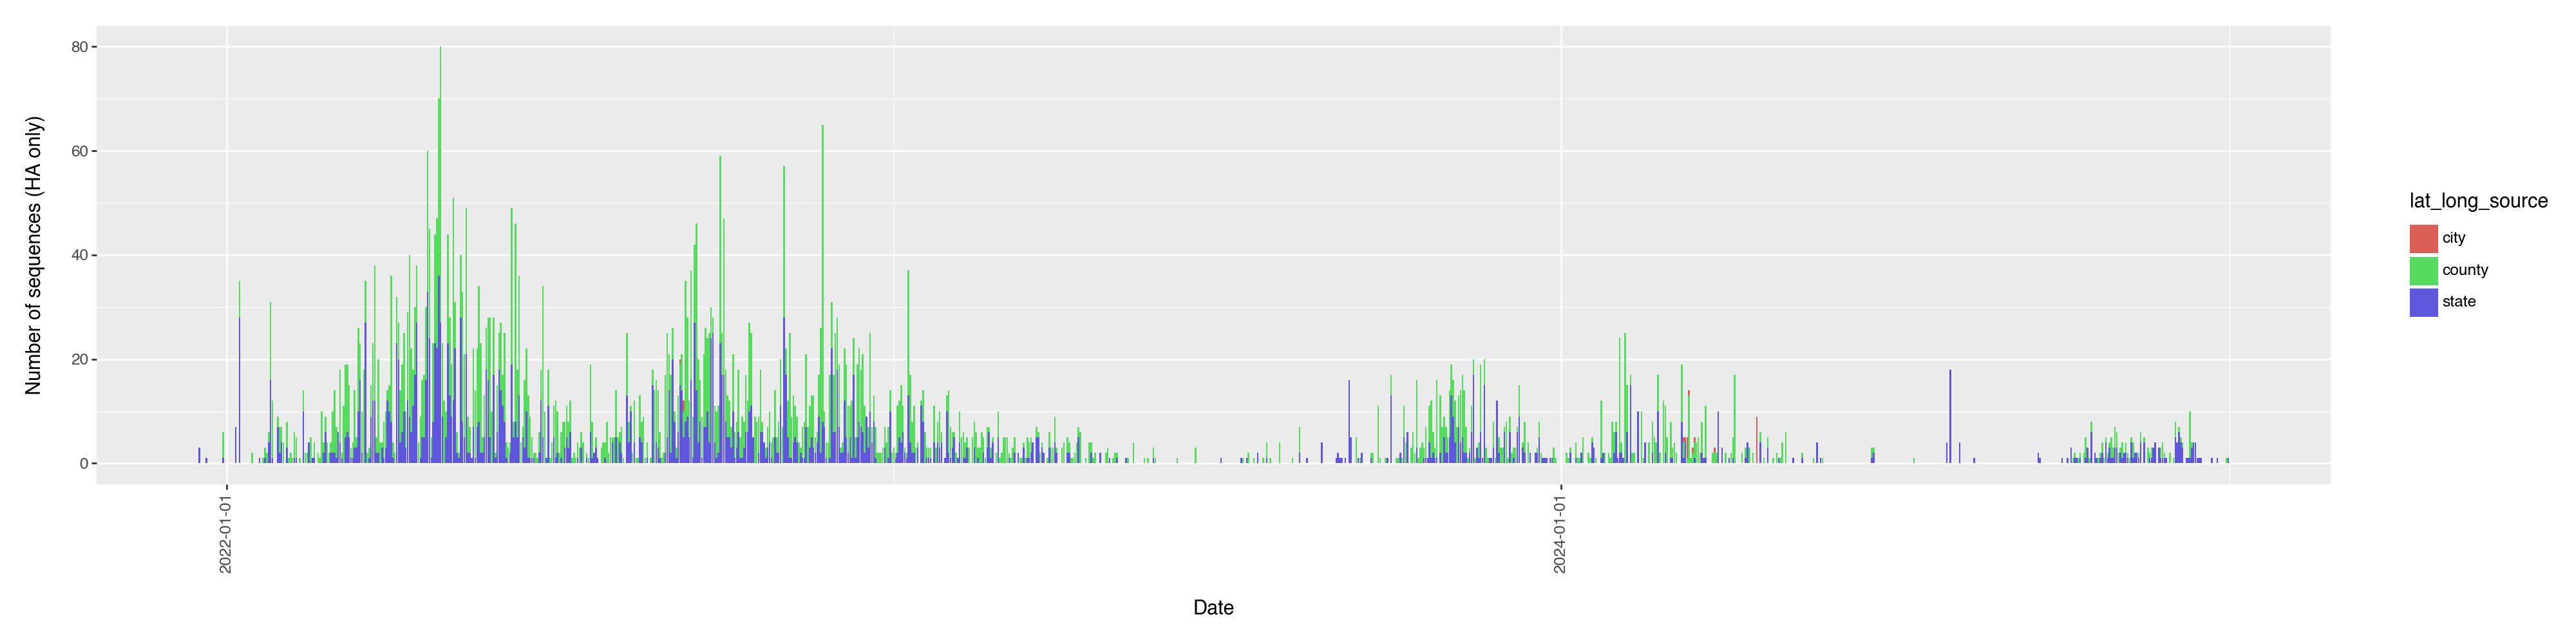

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 20 x 10 in image.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: ./metadata/exploratory_data_analysis/coordinate_source_over_time.png


In [6]:
# Plot some of this data!

print(metadata_wild_completefinescale["lat_long_source"].value_counts())

lat_long_source_overtime = (
    ggplot(metadata_wild_completefinescale, aes(x = "nonambig_date", fill = "lat_long_source"))
    + geom_bar(stat = "count")
    + labs(x = "Date", y = "Number of sequences (HA only)")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (20, 5))
)

lat_long_source_overtime.show()

lat_long_source_overtime.save(filename = './metadata/exploratory_data_analysis/coordinate_source_over_time.png', height=10, width=20, units = 'in', dpi=750)

In [79]:
# Can I figure out the overlap of bird species names?

# First, concatenate the two lists of hosts
total_hosts = pd.concat([metadata_hosts,detections_hosts], axis = 0, join = "outer", ignore_index = True)

total_hosts = total_hosts.rename({0:"hosts"}, axis = 1)

total_hosts.head()

# Next, plot the results
(
    ggplot(total_hosts, aes(x = "hosts"))
    + geom_bar(stat = "count")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (20, 5))
)

# If count = 2, then both metadata and detections have the same name for that host
# If count = 1, there is a missmatch

NameError: name 'metadata_hosts' is not defined

In [477]:
# Another way to visualize the above

# This time, merge the two lists of hosts and add a column for source
total_hosts_2 = metadata_hosts.merge(detections_hosts, on = 0, how = "outer", indicator = True)

total_hosts_2 = total_hosts_2.rename({0:"hosts"}, axis = 1)

mapper = {"right_only":"detection_data","left_only":"metadata","both":"both"}
total_hosts_2["source"] = total_hosts_2["_merge"].map(mapper)

total_hosts_2.head()

# Next, plot the results
(
    ggplot(total_hosts_2, aes(x = "hosts", fill = "source"))
    + geom_bar(stat = "count")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (20, 5))
)

NameError: name 'metadata_hosts' is not defined